#### Install Libraries

In [1]:
#%pip install numpy
#%pip install matplotlib

## Transform Images from CSV to image

#### Function to transform CSV to PNG

In [2]:
# Convert all rows in the CSV to individual PNGs (organized by label).
# The CSV rows are: label, pixel0, pixel1, ..., pixel783 (28x28 = 784 pixels).
import os
import numpy as np
from matplotlib import pyplot as plt
from matplotlib import image as mpimg

def transform_csv_to_png(csv_path, out_base):
    os.makedirs(out_base, exist_ok=True)

    # Load CSV skipping header (if header exists).
    try:
        data = np.genfromtxt(csv_path, delimiter=',', skip_header=1)
    except Exception as e:
        raise RuntimeError(f'Failed to read CSV: {e}')

    if data.size == 0:
        raise RuntimeError('No data loaded from CSV - check the file path and format.')

    labels = data[:, 0].astype(int)
    pixels = data[:, 1:]
    n = pixels.shape[0]
    print(f'Loaded {n} images (each should be 784 pixels)')

    # Count and display label distribution
    unique_labels, label_counts = np.unique(labels, return_counts=True)
    print(f'\nLabel distribution:')
    for label, count in zip(unique_labels, label_counts):
        print(f'  Label {label}: {count} images')
    print(f'Total unique labels: {len(unique_labels)}')

    # Save each image into a folder named by its label to keep dataset organized
    print(f'\nSaving {n} images...')
    for i in range(n):
        lab = int(labels[i])
        lab_dir = os.path.join(out_base, str(lab))
        os.makedirs(lab_dir, exist_ok=True)
        img = pixels[i].reshape(28, 28).astype(np.uint8)
        fname = os.path.join(lab_dir, f'{i}_label_{lab}.png')
        # Use vmin/vmax to avoid autoscaling issues
        plt.imsave(fname, img, cmap='gray', vmin=0, vmax=255)

    print('Saved all images under', out_base)


# Notes: Images are 28x28 (low resolution) so they look small; increase the figure size when plotting
# Grayscale is expected because each CSV pixel is a single intensity channel.
# Total images saved = total rows in the CSV (excluding header)


#### Tranform Traning MNIST SET

In [3]:
csv_path_train = './SignLengugeMNIST/sign_mnist_train/sign_mnist_train.csv'
out_base_train = './Dataset/convertedtopng/sign_mnist_train_all'
os.makedirs(out_base_train, exist_ok=True)

# We convert the training set here;
transform_csv_to_png(csv_path_train, out_base_train)

RuntimeError: Failed to read CSV: ./SignLengugeMNIST/sign_mnist_train/sign_mnist_train.csv not found.

#### Transform Test MNIST SET

In [ ]:
csv_path_test = './SignLengugeMNIST/sign_mnist_test/sign_mnist_test.csv'
out_base_test = './Dataset/convertedtopng/sign_mnist_test_all'
os.makedirs(out_base_test, exist_ok=True)

# We convert the test set here;
transform_csv_to_png(csv_path_test, out_base_test)

Loaded 7172 images (each should be 784 pixels)

Label distribution:
  Label 0: 331 images
  Label 1: 432 images
  Label 2: 310 images
  Label 3: 245 images
  Label 4: 498 images
  Label 5: 247 images
  Label 6: 348 images
  Label 7: 436 images
  Label 8: 288 images
  Label 10: 331 images
  Label 11: 209 images
  Label 12: 394 images
  Label 13: 291 images
  Label 14: 246 images
  Label 15: 347 images
  Label 16: 164 images
  Label 17: 144 images
  Label 18: 246 images
  Label 19: 248 images
  Label 20: 266 images
  Label 21: 346 images
  Label 22: 206 images
  Label 23: 267 images
  Label 24: 332 images
Total unique labels: 24

Saving 7172 images...
Saved all images under ./Dataset/convertedtopng/sign_mnist_test_all
Saved all images under ./Dataset/convertedtopng/sign_mnist_test_all


#### Display one sample image per label for both train and test sets

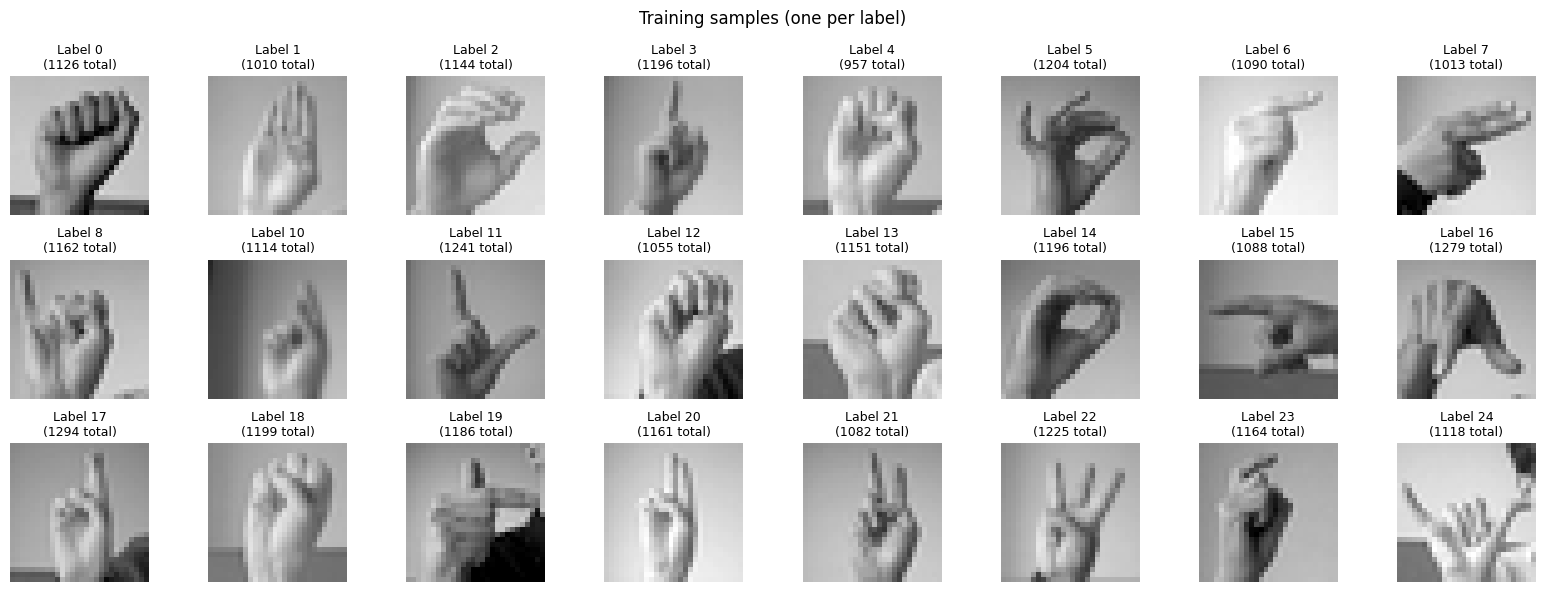

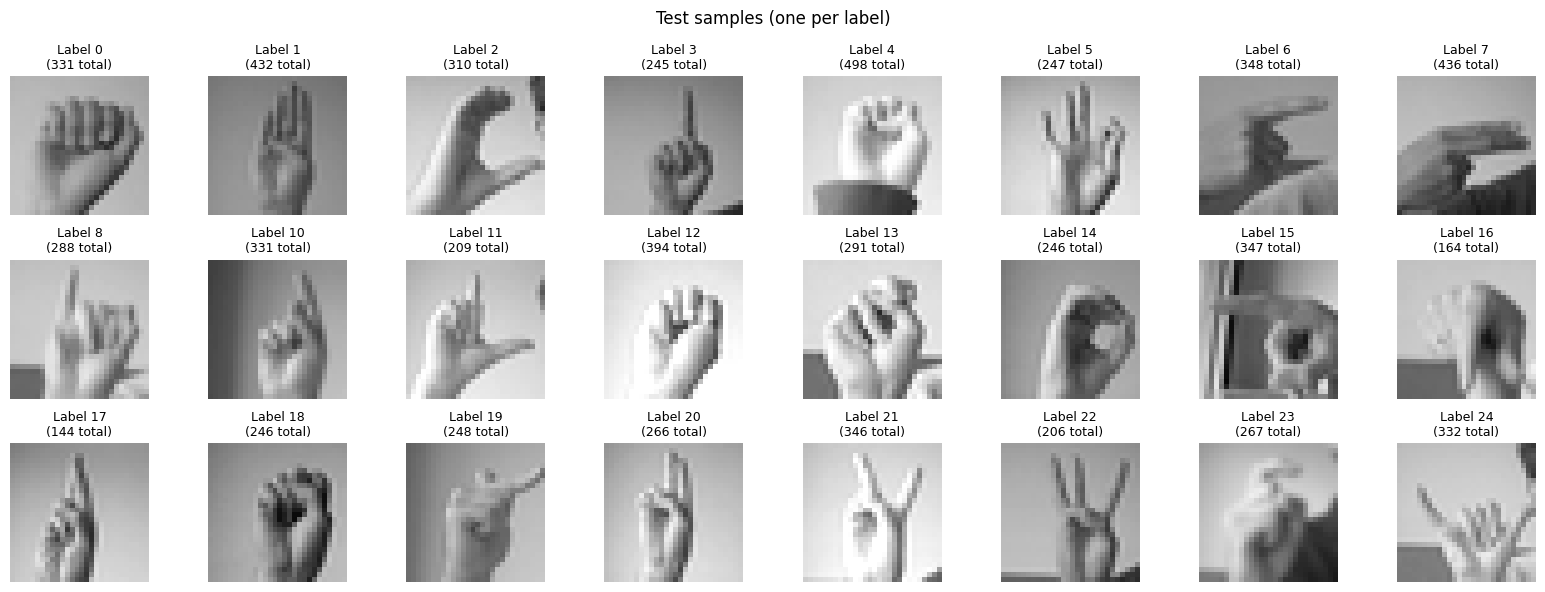

In [ ]:
# Display one sample image per label for both train and test sets
unique_labels = np.arange(0, 25)  # Labels are from 0 to 24
num_labels = len(unique_labels)
label_counts = []


def display_one_per_label(out_base, title, counts=None):
    cols = 8
    rows = (num_labels + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(2*cols, 2*rows))
    axes = axes.flatten()

    # compute counts if not provided
    if counts is None:
        counts = []
        for lab in unique_labels:
            lab_dir = os.path.join(out_base, str(int(lab)))
            if os.path.isdir(lab_dir):
                files = [f for f in os.listdir(lab_dir) if f.lower().endswith('.png')]
                counts.append(len(files))
            else:
                counts.append(0)

    for label_idx, lab in enumerate(unique_labels):
        lab_dir = os.path.join(out_base, str(int(lab)))
        sample_file = None
        if os.path.isdir(lab_dir):
            files = sorted([f for f in os.listdir(lab_dir) if f.lower().endswith('.png')])
            if files:
                sample_file = os.path.join(lab_dir, files[0])

        if sample_file:
            img = mpimg.imread(sample_file)
            axes[label_idx].imshow(img, cmap='gray')
        else:
            axes[label_idx].text(0.5, 0.5, 'No image', ha='center', va='center')
            axes[label_idx].set_facecolor('lightgray')

        axes[label_idx].set_title(f'Label {int(lab)}\n({counts[label_idx]} total)', fontsize=9)
        axes[label_idx].axis('off')

    for idx in range(num_labels, len(axes)):
        axes[idx].axis('off')

    fig.suptitle(title, fontsize=12)
    plt.tight_layout()
    plt.show()

# Display training (use existing label_counts for train)
display_one_per_label(out_base_train, 'Training samples (one per label)', counts=label_counts)

# Display test (counts will be computed from test folder)
display_one_per_label(out_base_test, 'Test samples (one per label)')
